# 02 · Limpieza, filtrado y transformación
El pipeline vive en `src/ypf_ds/data/clean.py` (reproducible e idempotente, corre en ~2 s con Polars). Acá lo ejecutamos, verificamos cada regla y mostramos las transformaciones de variables (encoding, escalado, variables derivadas).

> **Qué hace esta celda:** importa las librerías, carga la configuración del proyecto (rutas y umbrales de `src/ypf_ds/config.py`) y define el estilo de los gráficos.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, polars as pl, duckdb
import matplotlib.pyplot as plt, seaborn as sns
from ypf_ds import config
sns.set_theme(style="whitegrid", palette="deep"); plt.rcParams["figure.figsize"] = (11, 4.5)
config.DIR_FIGURAS.mkdir(parents=True, exist_ok=True)

> **Qué hace esta celda:** lee el dato crudo de Neuquina (antes de limpiar), ejecuta el pipeline de limpieza completo y guarda el resultado en `data/processed/` (panel pozo-mes y tabla de pozos).

In [2]:
from ypf_ds.data import clean
from ypf_ds.data.load import escanear_crudo
antes = escanear_crudo().collect()
panel, pozos = clean.construir()
print(f"Crudo: {antes.shape} → Panel Neuquina: {panel.shape} | Pozos: {pozos.height}")

Crudo: (421046, 24) → Panel Neuquina: (382992, 13) | Pozos: 4682


## Reglas aplicadas
| Paso | Regla |
|---|---|
| Filtro | `cuenca == NEUQUINA`, sin inyectores/sumideros/acuíferos ni pozos de servicio |
| Columnas | se descartan `vida_util`, `observaciones`, `iny_*`, metadata de carga |
| Negativos | producción < 0 → 0 |
| `tef` | acotado a [0, días del mes]; si hay producción con `tef = 0` → mes completo |
| Profundidad | fuera de [300, 8000] m → mediana del pozo → Capítulo IV → mediana (formación, yacimiento) → formación |
| Coordenadas | longitud > −60 → lat/lon invertidas, se intercambian |
| Operadora | última informada (981 pozos cambiaron de operadora) |
| Grilla | todos los meses desde el primer mes productivo; faltantes = 0 con `mes_faltante = True` |
| Fluido | `petroleo` si GOR acumulado < 3.000 m³/m³, si no `gas` |

> **Qué hace esta celda:** verifica cada regla comparando el conteo de problemas antes y después de la limpieza.

In [3]:
verif = pl.DataFrame({
    "chequeo": ["negativos", "tef > días del mes", "duplicados pozo-mes", "profundidad nula o imposible", "coord. invertidas"],
    "antes": [int((antes.filter(pl.col("cuenca")=="NEUQUINA")["prod_gas"] < 0).sum()),
              int((antes["tef"] > 31).sum()),
              antes.height - antes.unique(["idpozo","anio","mes"]).height,
              int(((antes["profundidad"] == 0) | (antes["profundidad"] > 8000)).sum()),
              int((antes["coordenadax"] > -60).sum())],
    "despues": [int((panel["prod_gas"] < 0).sum()), int((panel["tef"] > panel["dias_mes"]).sum()),
                panel.height - panel.unique(["idpozo","fecha"]).height,
                int(pozos["profundidad"].null_count()), int((pozos["lon"] > -60).sum())]})
verif

chequeo,antes,despues
str,i64,i64
"""negativos""",2,0
"""tef > días del mes""",15,0
"""duplicados pozo-mes""",0,0
"""profundidad nula o imposible""",5890,0
"""coord. invertidas""",68,0


> **Qué hace esta celda:** compara visualmente la profundidad y las coordenadas antes y después de la limpieza.

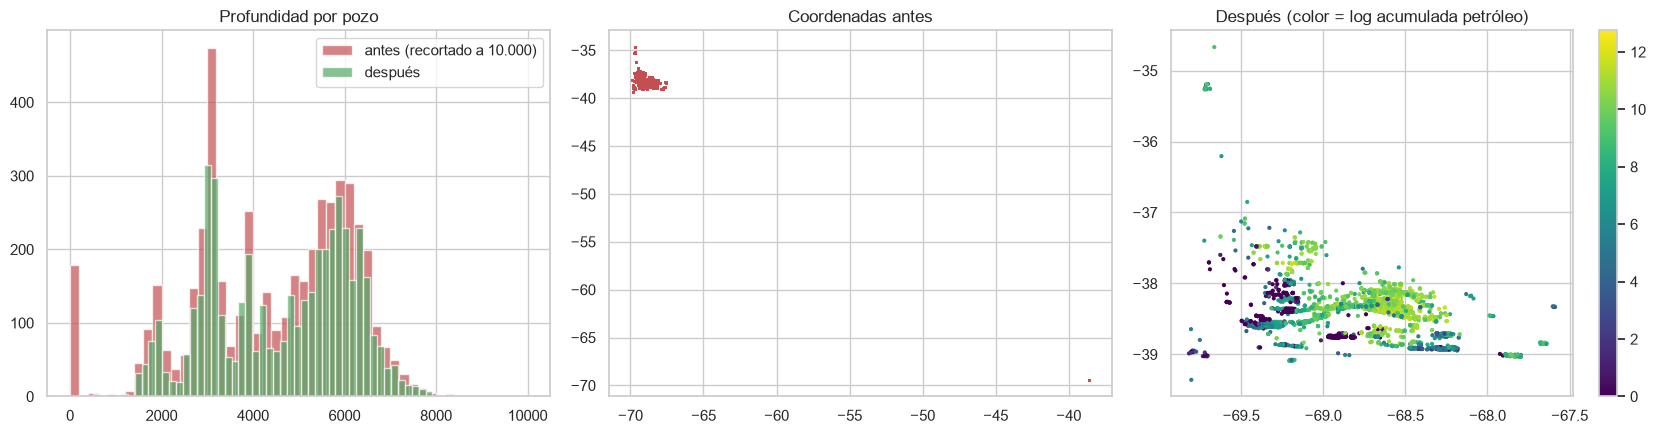

In [4]:
neu_antes = antes.filter(pl.col("cuenca") == "NEUQUINA")
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
pa = neu_antes.group_by("idpozo").agg(pl.col("profundidad").median())["profundidad"].to_numpy()
ax[0].hist(np.clip(pa, 0, 10000), bins=50, color="C3", alpha=.7, label="antes (recortado a 10.000)")
ax[0].hist(pozos["profundidad"], bins=50, color="C2", alpha=.7, label="después"); ax[0].legend(); ax[0].set_title("Profundidad por pozo")
ax[1].scatter(neu_antes["coordenadax"], neu_antes["coordenaday"], s=1, alpha=.3, color="C3"); ax[1].set_title("Coordenadas antes")
sc = ax[2].scatter(pozos["lon"], pozos["lat"], c=np.log1p(pozos["acum_pet"]), s=4, cmap="viridis")
ax[2].set_title("Después (color = log acumulada petróleo)"); plt.colorbar(sc, ax=ax[2])
plt.tight_layout(); plt.savefig(config.DIR_FIGURAS / "02_limpio.png", dpi=110); plt.show()

Después de la limpieza desaparecen las profundidades en 0 y el pozo con coordenadas invertidas; el mapa muestra la forma real de la cuenca, con los pozos más productivos concentrados en el núcleo de Vaca Muerta.

> **Qué hace esta celda:** cuenta pozos y producción total por tipo de fluido (clasificación por GOR).

In [5]:
pozos.group_by("fluido").agg(pl.len().alias("pozos"), pl.col("acum_pet").sum().round(0), pl.col("acum_gas").sum().round(0))

fluido,pozos,acum_pet,acum_gas
str,u32,f64,f64
"""petroleo""",2708,1.30891769e8,3.0470075e7
"""gas""",1974,9.151419e6,2.24716632e8


> **Qué hace esta celda:** muestra cuántos meses reconstruyó la grilla mensual y cuántos pozos quedan marcados como censurados (ya producían en 2006).

In [6]:
print(f"Meses reconstruidos por la grilla (mes_faltante): {int(panel['mes_faltante'].sum())} de {panel.height}")
print(f"Pozos censurados (ya producían al inicio del registro): {int(pozos['censurado_izq'].sum())}")
print(f"Pozos horizontales (sigla con '(h)'): {int(pozos['es_horizontal'].sum())} de {pozos.height}")

Meses reconstruidos por la grilla (mes_faltante): 566 de 382992
Pozos censurados (ya producían al inicio del registro): 57
Pozos horizontales (sigla con '(h)'): 2847 de 4682


## Complemento: padrón de pozos Capítulo IV (`capitulo-iv-pozos.csv`)
Padrón de 85.611 pozos de todo el país con cota, profundidad y **fechas de perforación y terminación**. Se une por `idpozo` y aporta datos conocidos *antes* de que el pozo produzca:
- `dias_perf`: duración de la perforación. `dias_term`: duración de la terminación (proxy de la cantidad de etapas de fractura).
- `es_horizontal`: la sigla del pozo termina en `(h)` cuando es horizontal (dato de la tabla de producción).

> **Qué hace esta celda:** mide la cobertura del Capítulo IV y compara, para pozos de petróleo de Vaca Muerta, la acumulada de 12 meses contra pozo horizontal, días de terminación y profundidad; calcula la correlación de Spearman.

Cobertura sobre los pozos de Neuquina:
shape: (1, 3)
┌─────────┬───────────┬───────────┐
│ cota    ┆ dias_perf ┆ dias_term │
│ ---     ┆ ---       ┆ ---       │
│ f64     ┆ f64       ┆ f64       │
╞═════════╪═══════════╪═══════════╡
│ 0.98334 ┆ 0.983127  ┆ 0.963691  │
└─────────┴───────────┴───────────┘


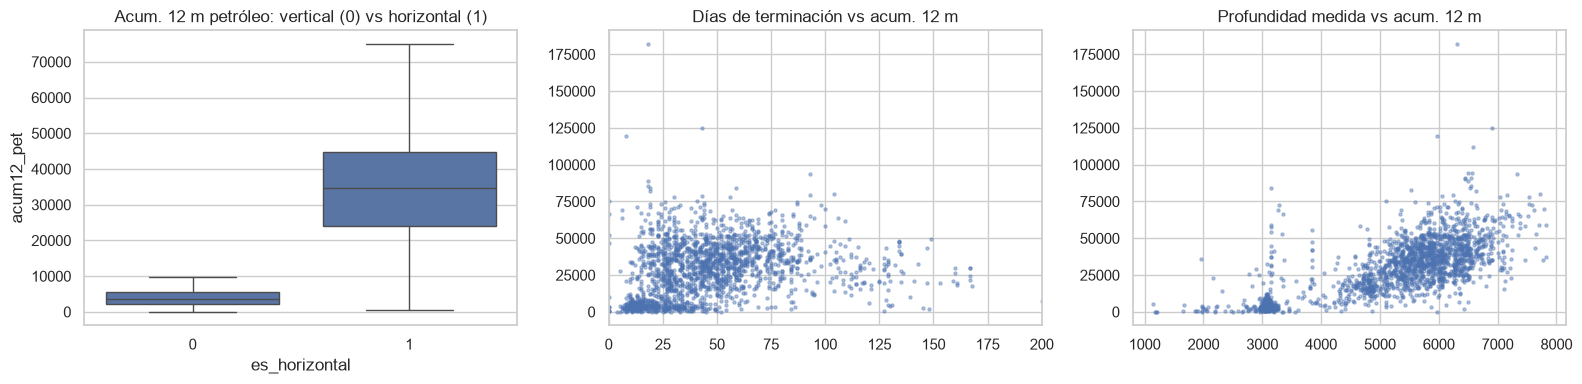

acum12_pet     1.000
dias_perf      0.386
dias_term      0.370
cota          -0.155
profundidad    0.734
anio_inicio    0.599
Name: acum12_pet, dtype: float64

In [7]:
print("Cobertura sobre los pozos de Neuquina:")
print(pozos.select(pl.col("cota", "dias_perf", "dias_term").is_not_null().mean()))
m12 = (panel.filter(pl.col("mes_produccion") <= 12).group_by("idpozo")
       .agg(acum12_pet=pl.col("prod_pet").sum(), n=pl.len()).filter(pl.col("n") == 12))
vm = (pozos.join(m12, on="idpozo")
      .filter((pl.col("formacion") == "vaca muerta") & (pl.col("tipopozo") == "Petrolífero")).to_pandas())
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.boxplot(data=vm, x="es_horizontal", y="acum12_pet", ax=ax[0], showfliers=False); ax[0].set_title("Acum. 12 m petróleo: vertical (0) vs horizontal (1)")
ax[1].scatter(vm.dias_term, vm.acum12_pet, s=5, alpha=.4); ax[1].set_title("Días de terminación vs acum. 12 m"); ax[1].set_xlim(0, 200)
ax[2].scatter(vm.profundidad, vm.acum12_pet, s=5, alpha=.4); ax[2].set_title("Profundidad medida vs acum. 12 m")
plt.tight_layout(); plt.savefig(config.DIR_FIGURAS / "02_capitulo_iv.png", dpi=110); plt.show()
vm[["acum12_pet", "dias_perf", "dias_term", "cota", "profundidad", "anio_inicio"]].corr(method="spearman")["acum12_pet"].round(3)

Los pozos **horizontales** de Vaca Muerta producen ~10 veces más que los verticales en su primer año, pero la **profundidad** ya capta gran parte de ese efecto (en un pozo horizontal es la *profundidad medida*, que incluye la rama lateral). En el entrenamiento se decide por **validación** si estas variables entran al modelo de pozo nuevo.

## Transformaciones (feature engineering)
Ver `src/ypf_ds/features/build.py`. Para cada pozo y mes de origen *t* se calculan, **solo con datos ≤ t**:
- `log1p` de petróleo, gas y agua del mes y lags 1, 2, 3, 6, 12; medias móviles 3 y 6.
- Pico histórico, producción/pico, acumulada, caudal por día efectivo, GOR, corte de agua, tendencia de 3 meses, meses desde el pico.
- Estáticas: formación, shale/tight, yacimiento, operadora (top 15 + OTRAS), profundidad, lat/lon, año de inicio.

> **Qué hace esta celda:** construye el dataset del modo A (pozo existente) para petróleo con horizonte 1 y compara el target en m³ (muy sesgado) con el target transformado (variación logarítmica).

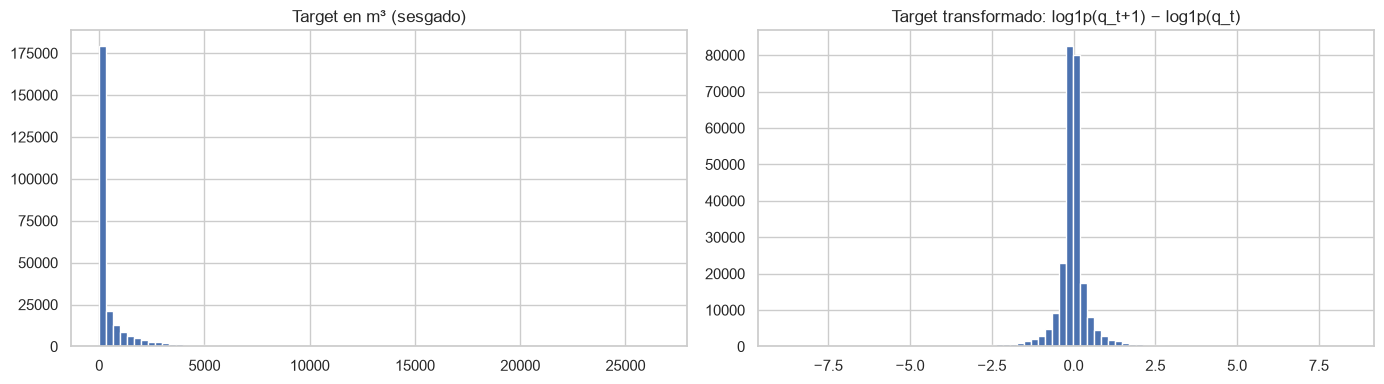

In [8]:
from ypf_ds.features import build as fb
dfa = fb.dataset_modo_a(panel, pozos, "petroleo", horizontes=[1])
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].hist(dfa["prod_obj"].to_numpy(), bins=80); ax[0].set_title("Target en m³ (sesgado)")
ax[1].hist(dfa["y"].to_numpy(), bins=80); ax[1].set_title("Target transformado: log1p(q_t+1) − log1p(q_t)")
plt.tight_layout(); plt.savefig(config.DIR_FIGURAS / "02_target.png", dpi=110); plt.show()

Modelar la **variación respecto del último mes** deja el target centrado y hace que el modelo aprenda la *declinación*. El modelo final usa el ratio `q[t+h]/q[t]` ponderado por volumen para no subestimar la media (ver notebook 03).

> **Qué hace esta celda:** calcula la correlación de Spearman de cada variable numérica con el target y grafica las 20 más correlacionadas.

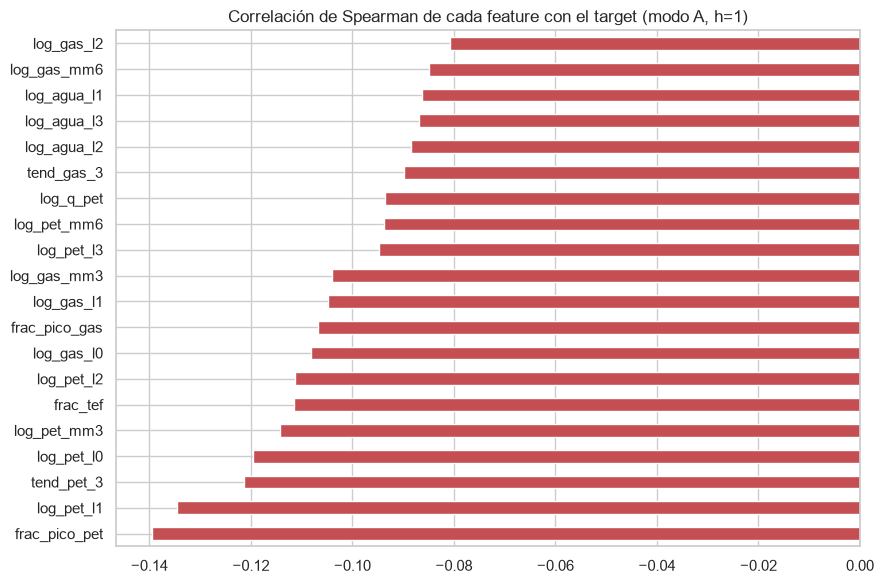

In [9]:
num_cols = [c for c in fb.columnas_modelo_a(dfa) if c not in fb.CATEGORICAS_A]
muestra = dfa.sample(100_000, seed=42).to_pandas()
corr_y = muestra[num_cols + ["y"]].corr(method="spearman")["y"].drop("y").dropna()
top = corr_y.reindex(corr_y.abs().sort_values(ascending=False).index).head(20)
ax = top.sort_values().plot.barh(color=np.where(top.sort_values() > 0, "C2", "C3"), figsize=(9, 6))
ax.set_title("Correlación de Spearman de cada feature con el target (modo A, h=1)"); ax.axvline(0, color="k", lw=.8)
plt.tight_layout(); plt.savefig(config.DIR_FIGURAS / "02_correlacion_target.png", dpi=110); plt.show()

Todas las correlaciones individuales son **débiles** (|ρ| ≤ 0,14) y **negativas**: los pozos que hoy producen más, están cerca de su pico (`frac_pico_pet`) o vienen subiendo (`tend_pet_3`) tienden a **declinar** el mes siguiente (un pozo en su pico solo puede bajar). Que ninguna variable sola explique el target justifica usar un modelo **no lineal** que combine muchas variables (notebook 03).

> **Qué hace esta celda:** muestra la matriz de correlación entre las features principales para detectar redundancias (multicolinealidad).

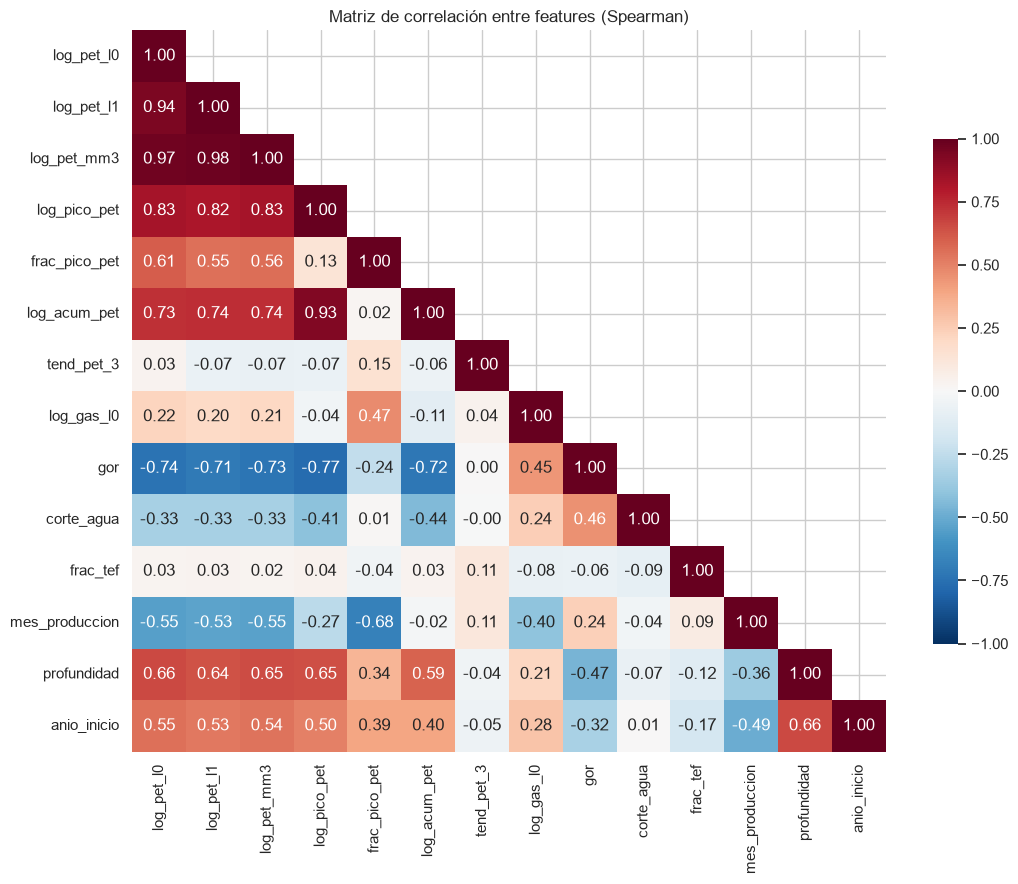

In [10]:
sel = ["log_pet_l0", "log_pet_l1", "log_pet_mm3", "log_pico_pet", "frac_pico_pet", "log_acum_pet", "tend_pet_3",
       "log_gas_l0", "gor", "corte_agua", "frac_tef", "mes_produccion", "profundidad", "anio_inicio"]
corr = muestra[sel].corr(method="spearman")
plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, mask=np.triu(np.ones_like(corr, bool), 1), cbar_kws={"shrink": .7})
plt.title("Matriz de correlación entre features (Spearman)")
plt.tight_layout(); plt.savefig(config.DIR_FIGURAS / "02_correlacion_features.png", dpi=110); plt.show()

Los lags y las medias móviles están muy correlacionados entre sí (≈0,9 o más). Para un modelo lineal eso sería un problema de **multicolinealidad**; para árboles (LightGBM) no lo es, porque el modelo elige en cada división la variable que más ayuda.

## Encoding y escalado
- **Encoding:** las categóricas se pasan como `category` nativo de LightGBM. Con *one-hot* el yacimiento sólo generaría 132 columnas.
- **Escalado:** los árboles no lo necesitan; sí se estandariza para Ridge, KNN y MLP (notebook 03) y para el clustering (notebook 04).

> **Qué hace esta celda:** muestra la cardinalidad (cantidad de valores distintos) de cada variable categórica: justifica no usar one-hot.

In [11]:
pd.DataFrame({c: [pozos[c].n_unique()] for c in ["formacion", "sub_tipo_recurso", "areayacimiento", "empresa", "tipopozo", "provincia"]},
             index=["valores distintos"]).T

,valores distintos
formacion,15
sub_tipo_recurso,3
areayacimiento,132
empresa,27
tipopozo,3
provincia,3


> **Qué hace esta celda:** compara tres escalados sobre la profundidad y la producción (log): original, estandarización (media 0, desvío 1) y normalización Min-Max (rango 0 a 1).

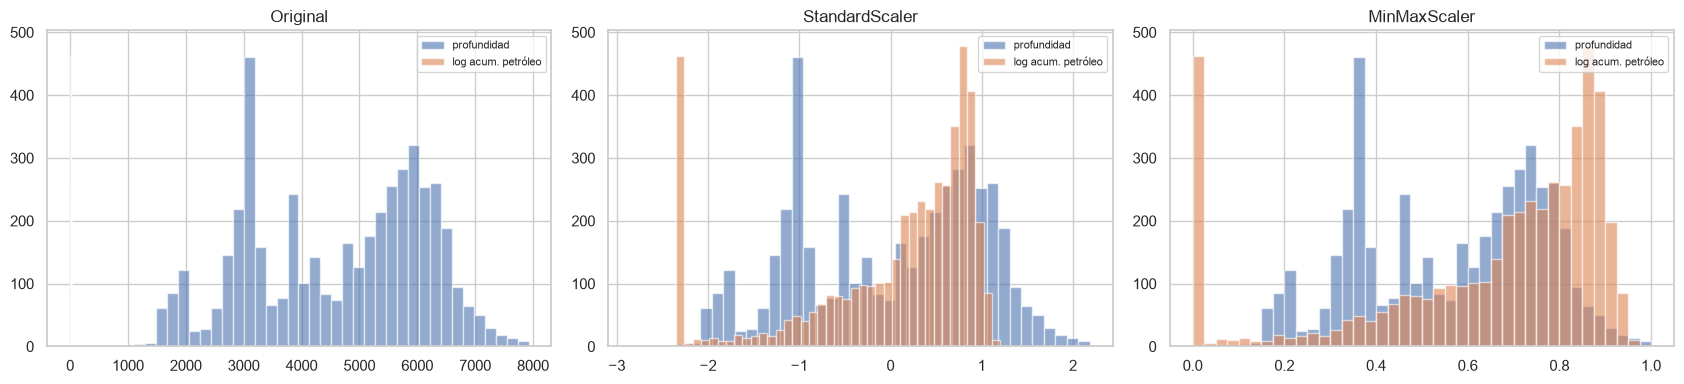

In [12]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler
datos = np.column_stack([pozos["profundidad"].to_numpy(), np.log1p(pozos["acum_pet"].to_numpy())])
versiones = {"Original": datos, "StandardScaler": StandardScaler().fit_transform(datos), "MinMaxScaler": MinMaxScaler().fit_transform(datos)}
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for a, (nombre, v) in zip(ax, versiones.items()):
    a.hist(v[:, 0], bins=40, alpha=.6, label="profundidad"); a.hist(v[:, 1], bins=40, alpha=.6, label="log acum. petróleo")
    a.set_title(nombre); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig(config.DIR_FIGURAS / "02_escalado.png", dpi=110); plt.show()

Sin escalar, la profundidad (miles de metros) dominaría cualquier cálculo de distancia (KNN, K-Means) frente a la producción en log (unidades). Ambos escalados ponen las variables en rangos comparables sin cambiar la **forma** de la distribución.

## Conclusiones de la limpieza y transformación
1. El pipeline deja **382.992 filas pozo-mes y 4.682 pozos** productores de la Cuenca Neuquina, sin negativos, sin duplicados, sin profundidades imposibles y con coordenadas corregidas (verificado con la tabla antes/después y con tests automáticos).
2. La **grilla mensual continua** garantiza que las variables temporales usen meses calendario reales.
3. El **Capítulo IV** se integra con 96–98 % de cobertura; su aporte real se decide por validación en el entrenamiento.
4. Ninguna feature sola explica el target (correlaciones débiles, todas de declinación) y hay fuerte redundancia entre lags: ambos puntos favorecen a los modelos de árboles.
5. Encoding nativo de categorías (alta cardinalidad) y escalado solo donde el algoritmo lo necesita.

➡️ El dataset limpio (`data/processed/`) es el insumo del modelado (notebook **03**).